# 03 Loss waterfall - PVDAQ system 9069 (Simon Solar Farm, GA)

Goal of Phase 3: break the gap between the nameplate energy at the measured irradiance and the
energy at the plant meter into causes, in kWh and USD, by year. `src/pv_loss_auditor/losses.py` does the work, this
notebook runs it, checks the assumptions behind it and states the conclusions.

Methodological decisions (options and trade-offs discussed before coding):
- **Sequential cascade** in physical order: nominal -> temperature -> design DC losses -> inverter ->
  clipping (= expected) -> downtime -> AC unknown -> channel credit -> running shortfall -> meter
  reconciliation -> after inverters (= meter). Each step is the difference of two neighbouring
  cumulative quantities, so the steps add up to (nominal - metered) by construction.
- **End point = plant meter 2** (revenue basis); the 2.2 % between inverters and meter is its own step.
- **Downtime vs data-channel loss:** a local day with sum(inverters) / (meter x 1.022) below 0.97 is a
  *channel-loss day*: the meter sees energy the inverter channels do not report. That energy is
  credited back (negative step), so zeros that are channel faults do not count as downtime.
- **Clipping:** model-based amount, cross-checked against measured steps at >= 98 % of the rating.

Everything in USD uses a flat 30.19 USD/MWh with a +-30 % band - see section 9 for what that is and is not.
Positive step = loss; a negative step is a gain (temperature in cold weather) or a credit.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

# Run from the project root so that `src` imports and relative paths in the config work.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd

from pv_loss_auditor import kpi, losses, model, plots, prices
from pv_loss_auditor import sensor_checks as sc
from pv_loss_auditor.data import load_clean
from pv_loss_auditor.config import load_config

pd.set_option("display.width", 170)
config = load_config("configs/system_9069.yaml")
FIG = Path("reports/figures")

## 1. Inputs and scope

The same inputs as in Phase 2 (flagged values already NaN). The waterfall covers only 5-min steps with
daylight, POA, cell temperature **and meter** known, so both sides of every difference cover the same
steps. Years are local calendar years; 2020 starts in May, 2023 ends in November.

In [2]:
inputs, ac = model.load_inputs(config)
t_cell = model.cell_temperature(inputs, config)
gamma = model.weighted_gamma(config)
day = inputs["daylight"]
scope = day & inputs["poa_wm2"].notna() & t_cell.notna() & inputs["p_ac_meter_kw"].notna()
year = inputs.index.tz_convert("America/New_York").year
cov = pd.DataFrame({"daylight steps": day.groupby(year).sum(), "in scope": scope.groupby(year).sum()})
cov["share in scope"] = (cov["in scope"] / cov["daylight steps"]).round(4)
cov

,daylight steps,in scope,share in scope
time_utc,,,
2020,36523,36234,0.9921
2021,53118,52304,0.9847
2022,53114,51803,0.9753
2023,49287,47155,0.9567


## 2. Waterfall by year

`check_closure` stops the run if any period is off by more than 1 kWh.

In [3]:
yearly = losses.loss_waterfall(inputs, ac, t_cell, config, gamma, freq="Y")
losses.check_closure(yearly)
cols = ["nominal_kwh"] + losses.STEPS + ["expected_kwh", "metered_kwh"]
print("GWh (positive step = loss):")
(yearly[cols] / 1e6).round(2).T

GWh (positive step = loss):


local_period,2020,2021,2022,2023
nominal_kwh,47.49,66.32,67.52,60.87
temperature,3.58,4.34,4.37,4.33
dc_losses,2.78,3.93,4.00,3.58
inverter,0.94,1.34,1.36,1.22
clipping,0.02,0.05,0.05,0.04
downtime,1.53,1.85,9.45,15.57
unknown_ac,0.17,0.03,0.03,0.01
channel_credit,-0.20,-0.19,-0.08,-4.79
running_shortfall,4.06,5.74,5.14,4.93
reconciliation,0.02,-0.18,0.10,-0.05


In [4]:
share = yearly[losses.STEPS].div(yearly["nominal_kwh"], axis=0) * 100
print("% of nominal energy:")
share.round(2).T

% of nominal energy:


local_period,2020,2021,2022,2023
temperature,7.54,6.54,6.47,7.11
dc_losses,5.86,5.92,5.93,5.89
inverter,1.98,2.03,2.01,2.00
clipping,0.05,0.07,0.08,0.06
downtime,3.21,2.79,13.99,25.58
unknown_ac,0.35,0.04,0.05,0.01
channel_credit,-0.42,-0.29,-0.12,-7.87
running_shortfall,8.55,8.65,7.62,8.10
reconciliation,0.05,-0.27,0.14,-0.08
after_inverters,1.57,1.60,1.37,1.27


Running inverters against the model: 1 - running shortfall / (expected - downtime - AC unknown).
Phase 2 reported 0.935 / 0.918 / 0.919 / 0.886 (2020-2023) with its own mask; the two should agree
in the trend (the 2023 step), the levels may differ because the masks differ.

In [5]:
running_expected = yearly["expected_kwh"] - yearly["downtime"] - yearly["unknown_ac"]
(1 - yearly["running_shortfall"] / running_expected).round(3)

local_period
2020    0.894
2021    0.895
2022    0.893
2023    0.864
Freq: Y-DEC, dtype: float64

The level differs from Phase 2 because that figure was a *median at POA 400-900 W/m2*, while this one
is energy-weighted over all lit steps, including weak light. The PVWatts model is linear in irradiance
(no low-light or AOI loss), so the plant should fall short of it at low POA. Check by POA bin
(running inverter-steps only, measured / expected):

In [6]:
n_inv = ac.shape[1]
_, down_states = kpi.inverter_states(ac, inputs["poa_wm2"], config)
scope_2d = pd.DataFrame(np.repeat(scope.to_numpy()[:, None], n_inv, axis=1), index=ac.index, columns=ac.columns)
running = ac.notna() & scope_2d & ~down_states
exp_ac = model.expected_power(inputs["poa_wm2"], t_cell, config, gamma)["p_ac_kw"]
poa_bin = pd.cut(inputs["poa_wm2"], [0, 100, 200, 400, 600, 800, 1500])
parts = pd.DataFrame({"measured": ac.where(running).sum(axis=1), "expected": exp_ac * running.sum(axis=1),
                      "year": year, "poa_bin": poa_bin})
g = parts.groupby(["year", "poa_bin"], observed=True)[["measured", "expected"]].sum()
print("measured / expected, running inverter-steps, by year and POA bin (W/m2):")
display((g["measured"] / g["expected"]).unstack().round(3))
print("share of the expected energy in each bin:")
(g["expected"].unstack().div(g["expected"].unstack().sum(axis=1), axis=0)).round(3)

measured / expected, running inverter-steps, by year and POA bin (W/m2):


poa_bin,"(0, 100]","(100, 200]","(200, 400]","(400, 600]","(600, 800]","(800, 1500]"
year,,,,,,
2020,0.714,0.822,0.874,0.913,0.915,0.901
2021,0.728,0.828,0.877,0.909,0.910,0.908
2022,0.683,0.831,0.877,0.908,0.909,0.905
2023,0.642,0.822,0.856,0.878,0.878,0.873


share of the expected energy in each bin:


poa_bin,"(0, 100]","(100, 200]","(200, 400]","(400, 600]","(600, 800]","(800, 1500]"
year,,,,,,
2020,0.026,0.047,0.134,0.178,0.255,0.361
2021,0.028,0.050,0.138,0.180,0.242,0.361
2022,0.028,0.050,0.124,0.170,0.244,0.385
2023,0.030,0.048,0.131,0.173,0.240,0.378


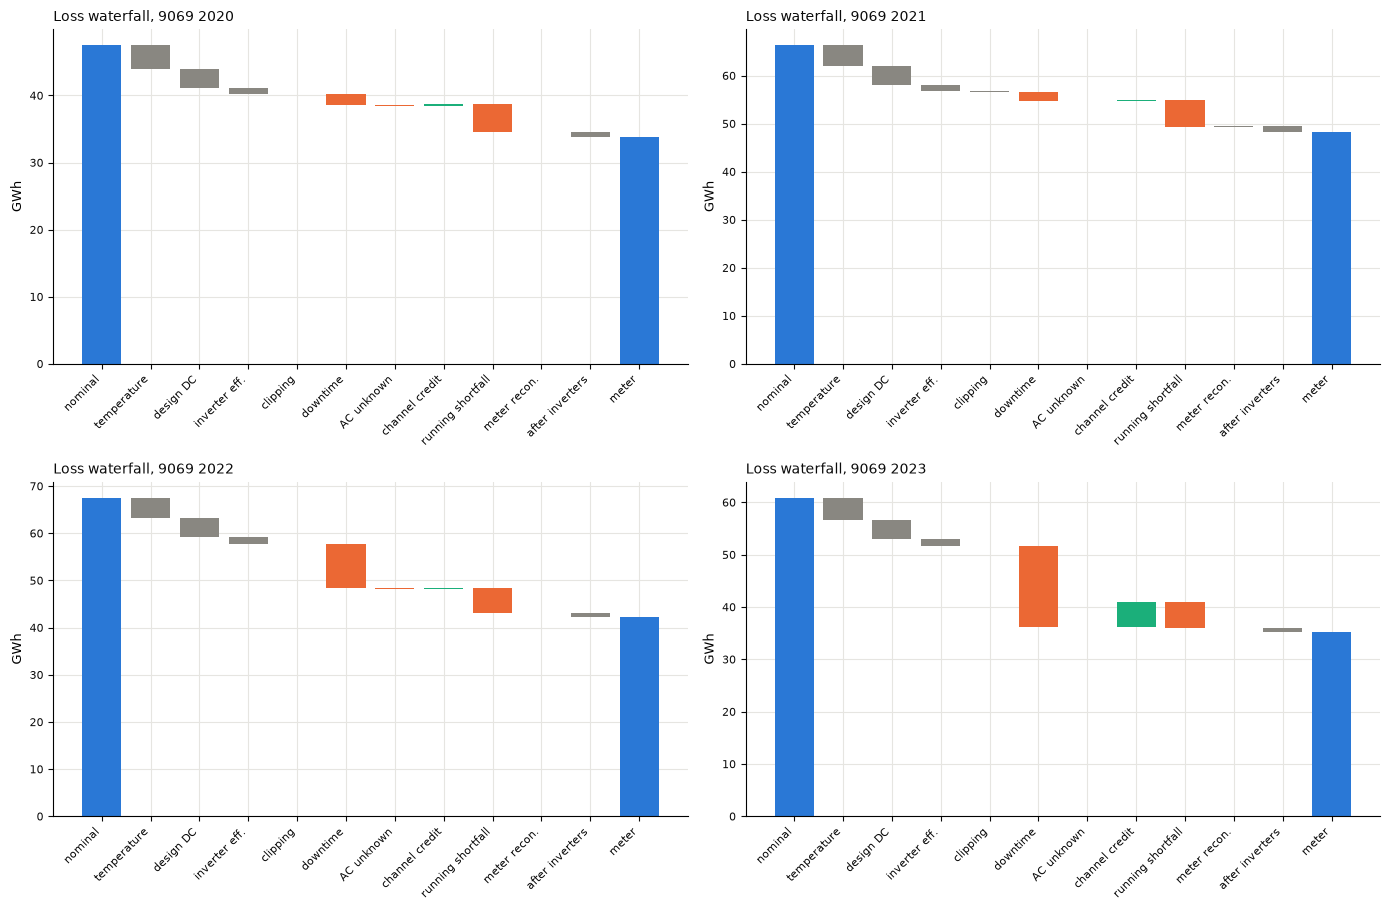

In [7]:
fig = plots.waterfall_plot(yearly, losses.STEPS, "Loss waterfall, 9069")
fig.savefig(FIG / "9069_loss_waterfall.png", dpi=130)

## 3. Causes over time (monthly)

,count,mean,std,min,25%,50%,75%,max
"design (temperature, DC, inverter, clipping)",43.0,0.142,0.032,0.083,0.118,0.145,0.167,0.184
downtime (net of channel loss),43.0,0.103,0.106,-0.000,0.009,0.082,0.166,0.402
running shortfall,43.0,0.083,0.017,0.053,0.071,0.081,0.094,0.143
"after inverters, meter reconciliation",43.0,0.014,0.003,0.001,0.013,0.013,0.016,0.019


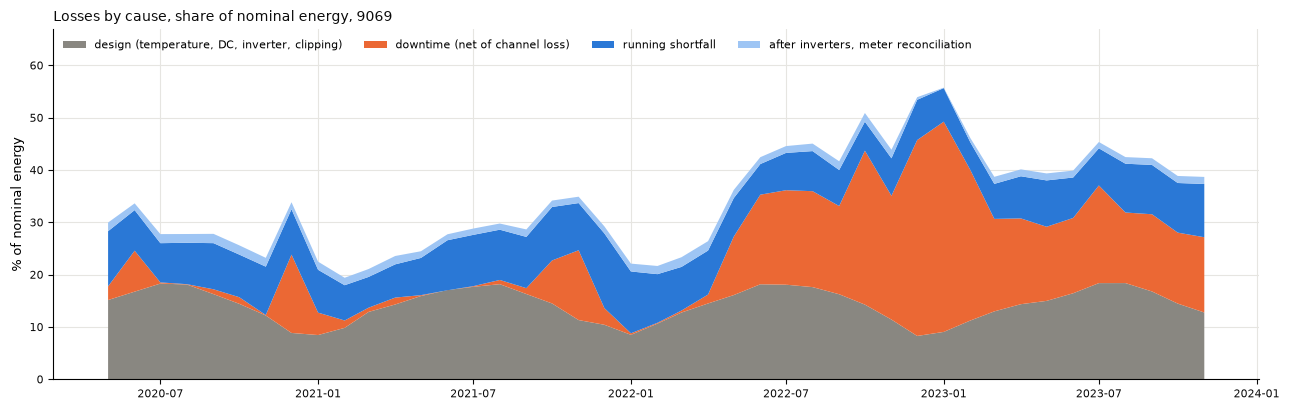

In [8]:
monthly = losses.loss_waterfall(inputs, ac, t_cell, config, gamma, freq="M")
losses.check_closure(monthly)
causes_m = losses.by_cause(monthly).div(monthly["nominal_kwh"], axis=0)
fig = plots.loss_causes_plot(causes_m, "Losses by cause, share of nominal energy, 9069")
fig.savefig(FIG / "9069_loss_causes_monthly.png", dpi=130)
causes_m.describe().T.round(3)

## 4. Check: the channel-loss tolerance (0.97)

The test is only trustworthy if, on days when the inverter channels are complete, the daily ratio
sum(inverters) / (meter x 1.022) stays above 0.97. Distribution of the daily ratio per year, and the
days below the threshold:

In [9]:
k = config["losses"]["inv_to_meter"]
dt = kpi.step_hours(inputs.index)
scope_2d = pd.DataFrame(np.repeat(scope.to_numpy()[:, None], ac.shape[1], axis=1), index=ac.index, columns=ac.columns)
s_known = ac.where(ac.notna() & scope_2d).sum(axis=1) * dt
m_kwh = (inputs["p_ac_meter_kw"] * dt).where(scope, 0.0) * k
local_day = kpi._period(inputs.index, "D")
daily = (s_known.groupby(local_day).sum() / m_kwh.groupby(local_day).sum()).dropna()
daily.index = daily.index.to_timestamp()
print("daily ratio per year:")
display(daily.groupby(daily.index.year).describe(percentiles=[0.01, 0.05, 0.5]).round(3))
low = daily < 1 - config["losses"]["channel_tolerance"]
print("days below threshold per year:", low.groupby(daily.index.year).sum().to_dict())
print("share of days:", low.groupby(daily.index.year).mean().round(3).to_dict())
early = low & (daily.index.year < 2023)
print("days below threshold by month, 2020-2022:")
low[early].groupby(daily.index[early].to_period("M")).size()

daily ratio per year:


,count,mean,std,min,1%,5%,50%,max
time_utc,,,,,,,,
2020,245.0,0.992,0.031,0.704,0.883,0.936,1.002,1.005
2021,363.0,0.989,0.023,0.860,0.885,0.944,0.996,1.006
2022,360.0,0.995,0.064,0.000,0.857,0.975,1.003,1.173
2023,320.0,0.871,0.090,0.634,0.658,0.672,0.909,0.978


days below threshold per year: {2020: 28, 2021: 40, 2022: 12, 2023: 281}
share of days: {2020: 0.114, 2021: 0.11, 2022: 0.033, 2023: 0.878}
days below threshold by month, 2020-2022:


time_utc
2020-05     2
2020-06    14
2020-12    12
2021-01    12
2021-02     1
2021-03     1
2021-06     2
2021-07     2
2021-10     5
2021-11    12
2021-12     5
2022-02     1
2022-05     2
2022-10     2
2022-12     7
Freq: M, dtype: int64

## 5. Check: order of steps

A sequential cascade depends on the order. The only pair with a visible cross term is temperature x
design DC losses (both are multiplicative): if the DC losses came first, the temperature loss would
be (1 - L) times smaller and the DC step the same amount larger. Size of that shift:

In [10]:
L = model.dc_loss_fraction(config)
shift = yearly["temperature"] * L
pd.DataFrame({"temperature step, GWh": yearly["temperature"] / 1e6,
              "shift if order swapped, GWh": shift / 1e6,
              "shift, % of nominal": shift / yearly["nominal_kwh"] * 100}).round(3)

,"temperature step, GWh","shift if order swapped, GWh","shift, % of nominal"
local_period,,,
2020,3.582,0.227,0.478
2021,4.340,0.275,0.415
2022,4.368,0.277,0.410
2023,4.326,0.274,0.450


## 6. Check: clipping - model against measurement

Model clipping is (DC after losses - unclipped AC limit). The measured counterpart is the number of
inverter-steps with AC >= 98 % of the rating (the clipping threshold of the cleaning). The model counts
steps as if all 40 inverters ran and performed exactly like the model, so it overstates the number of
steps at the limit: read it as an **upper bound**. The cell below also counts the AC peaks above the
rating (839-854 kW in Phase 2), which a model cannot produce.

In [11]:
rating = config["inverters"]["ac_kw"][0]["ac_kw"]
at_clip = (ac >= 0.98 * rating) & scope_2d
exp_p = model.expected_power(inputs["poa_wm2"], t_cell, config, gamma)["p_ac_kw"]
model_clip_steps = ((exp_p >= 0.98 * rating) & scope).groupby(year).sum() * ac.shape[1]
pd.DataFrame({
    "measured inverter-steps >= 98 %": at_clip.sum(axis=1).groupby(year).sum(),
    "model: inverter-steps >= 98 % (all 40 run)": model_clip_steps,
    "model clipping, MWh": (yearly["clipping"] / 1e3).set_axis(yearly.index.year),
    "share of nominal, %": share["clipping"].set_axis(yearly.index.year),
}).round(3)

,measured inverter-steps >= 98 %,model: inverter-steps >= 98 % (all 40 run),"model clipping, MWh","share of nominal, %"
2020,3600,17960,24.149,0.051
2021,12506,35120,46.378,0.070
2022,8873,39080,53.433,0.079
2023,2771,29080,36.577,0.060


In [12]:
over = (ac - rating).clip(lower=0).where(scope_2d & (ac > 1.0 * rating))
print(f"inverter-steps above the rating: {int(over.notna().sum().sum()):,} of {int((ac.notna() & scope_2d).sum().sum()):,}"
      f"  (> 830 kW: {int(((ac > 830) & scope_2d).sum().sum()):,}), max {ac.where(scope_2d).max().max():.0f} kW")
print(f"energy above the rating: {over.sum().sum() * dt / 1e3:.2f} MWh over the whole period")

inverter-steps above the rating: 2,023 of 7,490,635  (> 830 kW: 497), max 854 kW
energy above the rating: 0.65 MWh over the whole period


## 7. Check: curtailment (power limit) - is there a plateau?

The open question from Phase 2 was a "shelf" at ~0.19 of the rating and midday dips to zero. A power
limit would show as runs of >= 6 steps (30 min) with the output held within 0.5 kW between 5 % and 98 %
of the rating. The cleaning flags *identical* values as stale (and they become NaN in the waterfall),
so the check uses the raw values and reports how many plateau steps were already removed as stale.

In [13]:
inv_cols = list(ac.columns)
flag_cols = [f"flag_stale__{c}" for c in inv_cols]
raw = load_clean(config, columns=inv_cols + flag_cols + ["flag_daylight", "sun_elevation_deg"])
lit = raw["flag_daylight"].astype(bool)
plateau = sc.plateau_steps(raw[inv_cols].where(lit), rating)
stale = raw[flag_cols].astype(bool)
stale.columns = inv_cols
per_inv = pd.DataFrame({
    "plateau steps": plateau.sum(),
    "of them flagged stale": (plateau & stale).sum(),
    "daylight steps": lit.sum(),
})
per_inv["plateau, % of daylight"] = (per_inv["plateau steps"] / per_inv["daylight steps"] * 100).round(2)
display(per_inv.sort_values("plateau steps", ascending=False).head(8))
print("all inverters: plateau steps", int(plateau.sum().sum()), "| flagged stale", int((plateau & stale).sum().sum()),
      "| median per inverter", int(plateau.sum().median()))

,plateau steps,of them flagged stale,daylight steps,"plateau, % of daylight"
p_ac_inv02_kw,1335,1273,192042,0.70
p_ac_inv19_kw,899,894,192042,0.47
p_ac_inv20_kw,894,888,192042,0.47
p_ac_inv21_kw,839,823,192042,0.44
p_ac_inv22_kw,830,822,192042,0.43
p_ac_inv26_kw,826,803,192042,0.43
p_ac_inv25_kw,767,742,192042,0.40
p_ac_inv03_kw,305,293,192042,0.16


all inverters: plateau steps 7369 | flagged stale 7162 | median per inverter 15


In [14]:
# Plateau level of the steps that are not stale: a power limit would pile the levels up.
levels = raw[inv_cols].where(plateau & ~stale).stack() / rating
print("plateau level / rating, non-stale plateau steps:")
print(levels.describe().round(3))
hist, edges = np.histogram(levels, bins=np.arange(0.05, 1.0, 0.05))
pd.Series(hist, index=[f"{a:.2f}-{b:.2f}" for a, b in zip(edges[:-1], edges[1:])])

plateau level / rating, non-stale plateau steps:


count    207.000
mean       0.280
std        0.286
min        0.051
25%        0.073
50%        0.145
75%        0.493
max        0.855
dtype: float64


0.05-0.10    91
0.10-0.15    16
0.15-0.20    32
0.20-0.25     5
0.25-0.30     4
0.30-0.35     5
0.35-0.40     0
0.40-0.45     0
0.45-0.50     5
0.50-0.55     2
0.55-0.60     0
0.60-0.65     0
0.65-0.70     0
0.70-0.75    11
0.75-0.80    17
0.80-0.85    18
0.85-0.90     1
0.90-0.95     0
dtype: int64

## 8. Downtime by scale of the event

How many inverters are down at the same step: single (1), group (2-9), plant-wide (>= 10 of 40).
Downtime energy = expected AC of the down inverter-steps. Caveat: 2023 downtime contains channel
faults (credited back in the waterfall), so the 2023 numbers are an upper bound.

In [15]:
_, down_all = kpi.inverter_states(ac, inputs["poa_wm2"], config)
down = down_all & scope_2d
n_down = down.sum(axis=1)
e_down = n_down * exp_p * dt                           # kWh per step
scale = pd.cut(n_down, [0, 1, 9, 40], labels=["single (1)", "group (2-9)", "plant-wide (>=10)"])
tab = e_down.groupby([year, scale], observed=True).sum().unstack() / 1e6
tab["total"] = tab.sum(axis=1)
tab.round(2)

,single (1),group (2-9),plant-wide (>=10),total
time_utc,,,,
2020,0.12,0.81,0.60,1.53
2021,0.24,1.33,0.28,1.85
2022,0.14,5.68,3.64,9.45
2023,NaN,4.17,11.41,15.57


## 9. Value in USD

Flat price 30.19 USD/MWh (Georgia Power avoided energy cost 2026, "Solar Ground-Mounted Fixed Tilt",
Georgia PSC filing #223157) with a +-30 % band. **Read every USD figure with these limits:** (1) it is a
*projection* for 2026-2045 applied flat to 2020-2023 (realised wholesale prices in 2021-2022 were
higher); (2) it is the utility's avoided cost, not this plant's PPA price (unknown). The ranking of
causes in kWh does not depend on the price.

In [16]:
p_base, p_low, p_high = prices.price_usd_per_mwh(config)
print(f"price: {p_base:.2f} USD/MWh, band {p_low:.2f} ... {p_high:.2f}")
cause_kwh = losses.by_cause(yearly)
usd = losses.to_usd(cause_kwh, p_base, p_low, p_high)
summary = pd.DataFrame({
    "GWh, 2020-05..2023-11": cause_kwh.sum() / 1e6,
    "USD k, base": usd["base"].sum() / 1e3,
    "USD k, low": usd["low"].sum() / 1e3,
    "USD k, high": usd["high"].sum() / 1e3,
}).round(1)
print("whole period, by cause:")
display(summary)
print("USD k at the base price, by year:")
(usd["base"] / 1e3).round(0).T

price: 30.19 USD/MWh, band 21.13 ... 39.25
whole period, by cause:


,"GWh, 2020-05..2023-11","USD k, base","USD k, low","USD k, high"
"design (temperature, DC, inverter, clipping)",35.9,1085.0,759.5,1410.5
downtime (net of channel loss),23.4,705.5,493.8,917.1
running shortfall,19.9,599.9,419.9,779.9
"after inverters, meter reconciliation",3.4,102.8,71.9,133.6


USD k at the base price, by year:


local_period,2020,2021,2022,2023
"design (temperature, DC, inverter, clipping)",221.0,292.0,295.0,277.0
downtime (net of channel loss),45.0,51.0,284.0,326.0
running shortfall,123.0,173.0,155.0,149.0
"after inverters, meter reconciliation",23.0,27.0,31.0,22.0


## 10. Sensitivity: the assumed design DC losses

The 6.34 % design DC losses are an assumption (typical values, no PVsyst report for this plant); any
error moves energy between the "design DC" step and the running shortfall. Whole period, GWh:

In [17]:
sens = losses.dc_loss_sensitivity(inputs, ac, t_cell, config, gamma)
(sens / 1e6).round(2)

,dc_losses,downtime,running_shortfall
dc_loss_pct,,,
4.00,9.02,29.09,24.17
6.34,14.30,28.40,19.87
8.00,18.05,27.90,16.77


## 11. Conclusions

All figures: 2020-05 ... 2023-11, steps in scope (95.7-99.2 % of daylight steps per year), GWh at the
meter reference, USD at 30.19 USD/MWh (band 21.13 ... 39.25; a projection applied to 2020-2023, the
utility's avoided cost, not this plant's PPA price).

1. **The waterfall closes** in every year and month (closure < 1 kWh by construction and checked).
2. **Ranking of causes, whole period.** Design (temperature, assumed DC losses, inverter efficiency,
   clipping) 35.9 GWh / 1.09 M USD; **downtime net of channel loss 23.4 GWh / 0.71 M USD**
   (0.49 ... 0.92 M); **running shortfall 19.9 GWh / 0.60 M USD** (0.42 ... 0.78 M); after inverters
   3.4 GWh / 0.10 M USD. The design block is the plant as built (and an assumption), not recoverable;
   downtime + running shortfall = 43.3 GWh = **1.31 M USD (0.91 ... 1.70 M)** is what the audit points
   at. The ranking in kWh does not depend on the price.
3. **Downtime is the story of 2022-2023:** 3 % of nominal in 2020-2021, 14 % in 2022, 26 % in 2023.
   After the channel credit, 2023 downtime is 10.8 GWh (upper bound without credit: 15.6 GWh). By
   scale, 2023 downtime is mostly plant-wide (>= 10 inverters down at the same step, 11.4 of 15.6 GWh,
   inverters 01-06 off since 2022-12 included); in 2022 groups of 2-9 inverters dominate (5.7 of 9.5 GWh).
4. **Channel loss is a 2023 problem:** 4.8 GWh (about 145 k USD at the base price); on 88 % of the days
   in 2023 sum(inverters) / (meter x 1.022) is below 0.97 (median 0.91). In 2020-2022, 3-11 % of the
   days fall below 0.97, in clusters (2020-06, 2020-12, 2021-01, 2021-11); the credit there is
   0.1-0.2 GWh per year and offsets the "AC unknown" step (frozen inverters 02, 19-22, 25, 26 removed
   as stale), so the rule does not invent downtime or hide it in those years. Limits: it cannot say
   *which* inverter reports false zeros (per-inverter availability in 2023 stays undetermined), and it
   assumes the factor 1.022 is constant (1 pp of it moves the 2023 credit by about 0.35 GWh).
5. **Running shortfall** (inverters that run, against the model): 7.6-8.7 % of nominal. It is not
   uniform: measured / expected is 0.71-0.83 below 200 W/m2 (the linear PVWatts model has no
   low-light or AOI loss, so part of the shortfall is the model, not the plant) and about 0.91 above
   400 W/m2 in 2020-2022; in 2023 it falls by about 3 pp in every bin above 400 W/m2. The 2023 step is
   real, as in Phase 2. It still mixes soiling, degradation, the error of the assumed design losses
   and sensor bias: moving the design DC losses from 6.34 % to 4 % / 8 % adds 4.3 GWh to / takes 3.1 GWh away from this step (19.9 GWh -> 24.2 / 16.8)
   respectively; downtime stays within 0.7 GWh. It is split in Phase 4.
6. **Clipping is negligible** (0.05-0.08 % of nominal, at most 53 MWh a year, and an upper bound: the
   model counts 3-10 times more steps at the limit than are measured). **No curtailment found:** of
   7369 plateau steps (>= 30 min within 0.5 kW, 5-98 % of the rating) 97 % were already flagged stale
   (the known frozen inverters), the remaining 207 steps show no preferred level. The "shelf at 0.19"
   of Phase 2 is the weak-light part of a histogram, not a power limit. AC above the rating occurs in
   2,023 of 7.49 M inverter-steps (497 above 830 kW, max 854 kW), 0.65 MWh in total: left as measured.
7. **Order of steps** matters little: swapping temperature and design DC losses moves 0.23-0.28 GWh
   (0.41-0.48 % of nominal), small against downtime and the running shortfall.

Open for the next phases: split the running shortfall (soiling, degradation, AOI / low light) with
RdTools and a sensor comparison (Phase 4); anomaly detection on residuals will find the inverters
and periods behind the shortfall (Phase 5); which inverter reports false zeros in 2023 needs the
channel-level data from the operator, it cannot be recovered from these files.